In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [6]:
df = pd.read_csv('sales_data_sample.csv',encoding = 'ISO-8859-1')

In [7]:
df.columns

Index(['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER',
       'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID',
       'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE',
       'ADDRESSLINE1', 'ADDRESSLINE2', 'CITY', 'STATE', 'POSTALCODE',
       'COUNTRY', 'TERRITORY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME',
       'DEALSIZE'],
      dtype='str')

In [9]:
features = ['QUANTITYORDERED', 'PRICEEACH', 'SALES']

In [11]:
X = df[features]

In [12]:
sc = StandardScaler()
X_Scaled = sc.fit_transform(X)

In [14]:
inertia =  []
for k in range(1,11):
    knn = KMeans(n_clusters=k , random_state = 42, n_init = 10)
    knn.fit(X_Scaled)
    inertia.append(knn.inertia_)

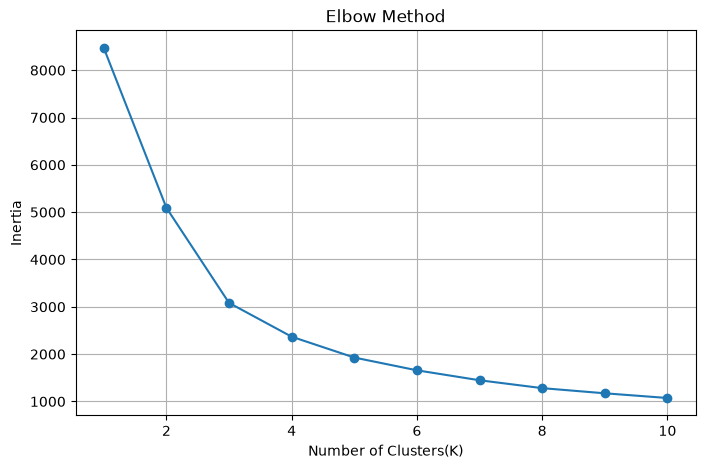

In [17]:
plt.figure(figsize=(8,5))
plt.plot(range(1,11),inertia,marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters(K)")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

In [21]:
k = 3
kmeans = KMeans(n_clusters = k, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_Scaled)

In [23]:
print(" CLuster Count ")
print(df["cluster"].value_counts().sort_index())

 CLuster Count 
cluster
0     881
1     907
2    1035
Name: count, dtype: int64


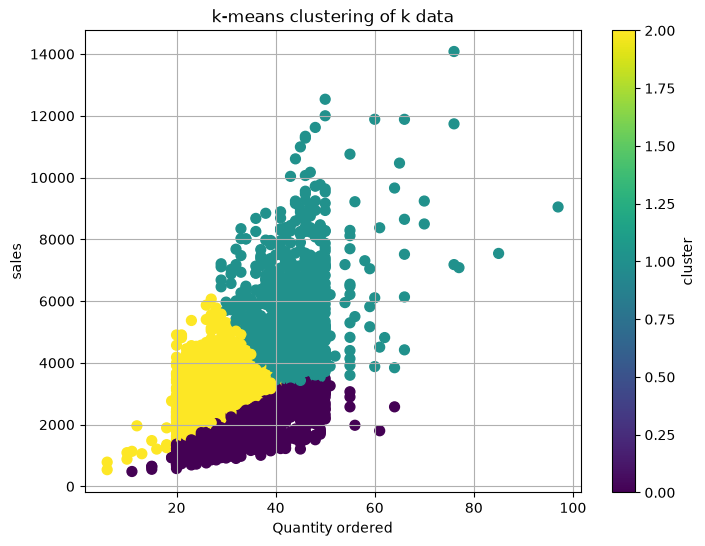

In [27]:
plt.figure(figsize=(8,6))
plt.scatter(df['QUANTITYORDERED'],df['SALES'],c=df['cluster'],cmap='viridis',s=50)
plt.title("k-means clustering of k data")
plt.xlabel("Quantity ordered")
plt.ylabel("sales")
plt.grid()
plt.colorbar(label='cluster')
plt.show()
